# PreTest 01: Binary Classification แบบครบวงจร — การพยากรณ์ฝนตกในวันถัดไป
### จากข้อมูลดิบ → ทำความสะอาด → Visualization → เตรียมข้อมูล → เทรน 3 โมเดล → วัดผล → เลือกโมเดล

> **ที่มา:** ดัดแปลงและขยายจาก Kaggle Notebook
> [Logistic Regression Classifier Tutorial](https://www.kaggle.com/code/prashant111/logistic-regression-classifier-tutorial) โดย Prashant Banerjee
> สิ่งที่เพิ่ม/แก้: คำอธิบายภาษาไทยทุกขั้นตอน, ลบแถวที่ Target หาย, แก้การอ่าน Confusion Matrix ให้ถูกต้อง,
> คำนวณขอบ Outlier จาก Train Set เท่านั้น, เพิ่มโมเดล **Decision Tree** และ **Random Forest**, ตารางเปรียบเทียบ 3 โมเดล
>
> **ชุดข้อมูล (Dataset):** [Rain in Australia](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package) — ข้อมูลอากาศรายวัน ~10 ปี จาก 49 เมืองในออสเตรเลีย

---

## ภาพรวมขั้นตอน (สามารถใช้เป็นโครงสร้างในการทำข้อสอบได้)

| ขั้น | งาน | คำถามที่ต้องตอบ |
|---|---|---|
| 1 | กำหนดโจทย์ | ทำนายอะไร? เป็น Classification หรือ Regression? วัดผลด้วยอะไร? |
| 2 | โหลดข้อมูล | ข้อมูลมีกี่แถว กี่คอลัมน์? |
| 3 | สำรวจข้อมูลเบื้องต้น | แต่ละคอลัมน์คืออะไร ชนิดข้อมูลถูกหรือไม่ |
| 4 | ทำความสะอาด (Data Cleaning) | Target หายหรือไม่ ซ้ำหรือไม่ ค่าหายเท่าใด |
| 5 | EDA & Visualization | Target สมดุลหรือไม่ มี Outlier หรือไม่ ตัวแปรไหนสัมพันธ์กับ Target? |
| 6 | เตรียมข้อมูล (Preprocessing) | Split → จัดการ Outlier → เติมค่าหาย → Encode → Scale |
| 7–9 | เทรนโมเดล 3 ตัว | Logistic Regression, Decision Tree, Random Forest |
| 10 | เปรียบเทียบและเลือกโมเดล | ตัวไหนดีที่สุด เพราะอะไร? |

> **หลักการสำคัญ:** ทุกอย่างที่ "เรียนรู้จากข้อมูล" (ค่า median, mode, ขอบ outlier, min/max ของ scaler)
> ต้องคำนวณจาก **Train Set เท่านั้น** แล้วค่อยนำไปใช้กับ Test Set (มิฉะนั้นจะเกิด Data Leakage)

---
# ขั้นที่ 1: กำหนดโจทย์ (Problem Definition)

- **เป้าหมาย:** ใช้ข้อมูลอากาศ **วันนี้** ทำนายว่า **พรุ่งนี้ฝนจะตกหรือไม่** (`RainTomorrow` = Yes / No)
- **ประเภทปัญหา:** Target มีเพียง 2 ค่า → **Binary Classification**
- **วัดผลด้วย:** Accuracy, Precision, Recall, F1-score, ROC-AUC (จะอธิบายทีละตัวในขั้นที่ 7)

---
# ขั้นที่ 2: นำเข้าไลบรารีและโหลดข้อมูล

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')            # ซ่อนคำเตือนที่ไม่สำคัญ ให้อ่าน output ง่ายขึ้น
pd.set_option('display.max_columns', 50)     # ให้แสดงคอลัมน์ได้ครบ
sns.set_theme(style='whitegrid')

โค้ดด้านล่างจะหาไฟล์ในโฟลเดอร์ `Data/` ก่อน ถ้าไม่มี (เช่นเปิดบน Google Colab) จะดาวน์โหลดจาก Kaggle ให้อัตโนมัติด้วย `kagglehub`

In [2]:
DATA_FILE = "Data/weatherAUS.csv"

if not os.path.exists(DATA_FILE):
    # ไม่มีไฟล์ในเครื่อง → ดาวน์โหลดจาก Kaggle (ถ้า error ให้รัน !pip install kagglehub ก่อน)
    import kagglehub
    folder = kagglehub.dataset_download("jsphyg/weather-dataset-rattle-package")
    DATA_FILE = os.path.join(folder, "weatherAUS.csv")

df = pd.read_csv(DATA_FILE)
print("ขนาดข้อมูล (แถว, คอลัมน์):", df.shape)

ขนาดข้อมูล (แถว, คอลัมน์): (145460, 23)


---
# ขั้นที่ 3: สำรวจข้อมูลเบื้องต้น (First Look)
### 3.1 ดูตัวอย่างข้อมูล 5 แถวแรก

In [3]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### 3.2 ความหมายของแต่ละคอลัมน์ (Data Dictionary)

| คอลัมน์ | ความหมาย | ชนิด |
|---|---|---|
| `Date` | วันที่ | ข้อความ (ต้องแปลง) |
| `Location` | เมืองที่วัด (49 เมือง) | Categorical |
| `MinTemp`, `MaxTemp` | อุณหภูมิต่ำสุด/สูงสุด (°C) | Numerical |
| `Rainfall` | ปริมาณฝนวันนี้ (มม.) | Numerical |
| `Evaporation` | ปริมาณการระเหย (มม.) | Numerical |
| `Sunshine` | จำนวนชั่วโมงแดด | Numerical |
| `WindGustDir`, `WindGustSpeed` | ทิศ/ความเร็วลมกระโชกแรงสุด | Cat / Num |
| `WindDir9am`, `WindDir3pm` | ทิศลมตอน 9 โมง / บ่าย 3 | Categorical |
| `WindSpeed9am`, `WindSpeed3pm` | ความเร็วลม (กม./ชม.) | Numerical |
| `Humidity9am`, `Humidity3pm` | ความชื้น (%) | Numerical |
| `Pressure9am`, `Pressure3pm` | ความกดอากาศ (hPa) | Numerical |
| `Cloud9am`, `Cloud3pm` | ปริมาณเมฆ (0–8 ส่วน) | Numerical |
| `Temp9am`, `Temp3pm` | อุณหภูมิ ณ เวลานั้น (°C) | Numerical |
| `RainToday` | วันนี้ฝนตกหรือไม่ (ฝน > 1 มม.) | Categorical (Yes/No) |
| **`RainTomorrow`** | **พรุ่งนี้ฝนตกหรือไม่ ← Target** | Categorical (Yes/No) |

### 3.3 ชนิดข้อมูลและจำนวนค่าที่ไม่หาย (`info`)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

> **ข้อสังเกต:** `Non-Null Count` ของหลายคอลัมน์น้อยกว่า 145,460 แปลว่า **มีค่าหาย (Missing) จำนวนมาก**
> เช่น `Sunshine`, `Evaporation`, `Cloud9am` หายเกือบครึ่ง

### 3.4 สถิติสรุปของตัวแปรตัวเลข (`describe`)

In [5]:
df.describe().round(2)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.00,144199.00,142199.00,82670.00,75625.00,135197.00,143693.00,142398.00,142806.00,140953.00,130395.00,130432.00,89572.00,86102.00,143693.00,141851.00
mean,12.19,23.22,2.36,5.47,7.61,40.04,14.04,18.66,68.88,51.54,1017.65,1015.26,4.45,4.51,16.99,21.68
std,6.40,7.12,8.48,4.19,3.79,13.61,8.92,8.81,19.03,20.80,7.11,7.04,2.89,2.72,6.49,6.94
min,-8.50,-4.80,0.00,0.00,0.00,6.00,0.00,0.00,0.00,0.00,980.50,977.10,0.00,0.00,-7.20,-5.40
25%,7.60,17.90,0.00,2.60,4.80,31.00,7.00,13.00,57.00,37.00,1012.90,1010.40,1.00,2.00,12.30,16.60
50%,12.00,22.60,0.00,4.80,8.40,39.00,13.00,19.00,70.00,52.00,1017.60,1015.20,5.00,5.00,16.70,21.10
75%,16.90,28.20,0.80,7.40,10.60,48.00,19.00,24.00,83.00,66.00,1022.40,1020.00,7.00,7.00,21.60,26.40
max,33.90,48.10,371.00,145.00,14.50,135.00,130.00,87.00,100.00,100.00,1041.00,1039.60,9.00,9.00,40.20,46.70


> **ข้อสังเกต:** ดู `Rainfall`: ค่า 75% (Q3) = 0.8 มม. แต่ max = 371 มม. → การกระจาย **เบ้ขวามาก** และน่าจะมี **Outlier**
> (`WindSpeed9am`, `Evaporation` ก็มีลักษณะคล้ายกัน) จะตรวจละเอียดในขั้นที่ 5

---
# ขั้นที่ 4: ทำความสะอาดข้อมูล (Data Cleaning)

### 4.1 ลบแถวที่ไม่มีคำตอบ (Target หาย)
แถวที่ไม่รู้ว่าพรุ่งนี้ฝนตกหรือไม่ **ใช้สอนโมเดลไม่ได้** และ **ห้ามประมาณค่า Target ขึ้นเอง** (เพราะจะเป็นการสร้างคำตอบปลอมขึ้นมาเอง)

In [6]:
print("Target หายไป:", df['RainTomorrow'].isnull().sum(), "แถว")

df = df.dropna(subset=['RainTomorrow'])
print("ขนาดหลังลบ:", df.shape)

Target หายไป: 3267 แถว
ขนาดหลังลบ: (142193, 23)


### 4.2 ตรวจข้อมูลซ้ำ (Duplicates)

In [7]:
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 0


> **ผลลัพธ์:** ไม่มีแถวซ้ำ (ถ้ามี ใช้ `df = df.drop_duplicates()`)

### 4.3 แยกตัวแปรเป็น Categorical และ Numerical
ทั้งสองแบบต้องจัดการต่างกัน (เติมค่าหายต่างวิธี, Encode เฉพาะ Categorical, Scale เฉพาะ Numerical)

In [8]:
categorical = [col for col in df.columns if df[col].dtype == 'object']
numerical   = [col for col in df.columns if df[col].dtype != 'object']

print(f"Categorical ({len(categorical)}):", categorical)
print(f"Numerical   ({len(numerical)}):", numerical)

Categorical (7): ['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
Numerical   (16): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


### 4.4 สำรวจค่าที่หาย (Missing Values)

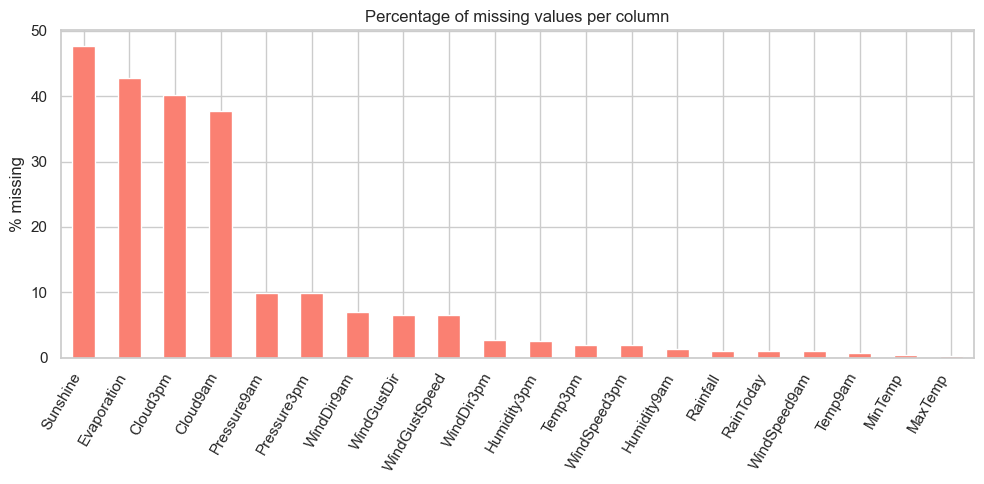

,% ที่หาย
Sunshine,47.69
Evaporation,42.79
Cloud3pm,40.15
Cloud9am,37.74
Pressure9am,9.86
Pressure3pm,9.83
WindDir9am,7.04
WindGustDir,6.56
WindGustSpeed,6.52
WindDir3pm,2.66


In [9]:
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

plt.figure(figsize=(10, 5))
missing.plot(kind='bar', color='salmon')
plt.ylabel('% missing')
plt.title('Percentage of missing values per column')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

missing.round(2).to_frame('% ที่หาย')

> **ตัดสินใจ:** แม้ `Sunshine` จะหายเกือบ 50% แต่เราจะ **ไม่ลบคอลัมน์** และจะเติมด้วยค่า median ในขั้นที่ 6
> (ทำหลังแบ่ง Train/Test เพื่อป้องกัน Data Leakage) — ในงานจริงอาจทดลองทั้งแบบลบและไม่ลบ แล้วเทียบผล

### 4.5 จำนวนหมวดหมู่ในแต่ละตัวแปร Categorical (Cardinality)
หากมีจำนวนหมวดหมู่มาก การทำ One-Hot Encoding จะสร้างคอลัมน์จำนวนมาก

In [10]:
for col in categorical:
    print(f"{col:13s} มี {df[col].nunique():5d} ค่า")

Date          มี  3436 ค่า
Location      มี    49 ค่า
WindGustDir   มี    16 ค่า
WindDir9am    มี    16 ค่า
WindDir3pm    มี    16 ค่า
RainToday     มี     2 ค่า
RainTomorrow  มี     2 ค่า


> **ข้อสังเกต:** `Date` มีกว่า 3,000 ค่า (เพราะเป็นวันที่) → **ไม่ควรทำ One-Hot Encoding โดยตรง** ต้องแยกเป็นปี/เดือน/วันก่อน

### 4.6 Feature Engineering: แยกวันที่เป็น ปี / เดือน / วัน
`Month` น่าจะมีประโยชน์ เพราะฤดูกาลมีผลต่อฝน

In [11]:
df['Date']  = pd.to_datetime(df['Date'])   # แปลงข้อความเป็นชนิดวันที่
df['Year']  = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day']   = df['Date'].dt.day
df = df.drop(columns='Date')                # ลบคอลัมน์เดิมทิ้ง

df[['Year', 'Month', 'Day']].head()

,Year,Month,Day
0,2008,12,1
1,2008,12,2
2,2008,12,3
3,2008,12,4
4,2008,12,5


---
# ขั้นที่ 5: EDA & Visualization

### 5.1 ความสมดุลของ Target (Class Balance)

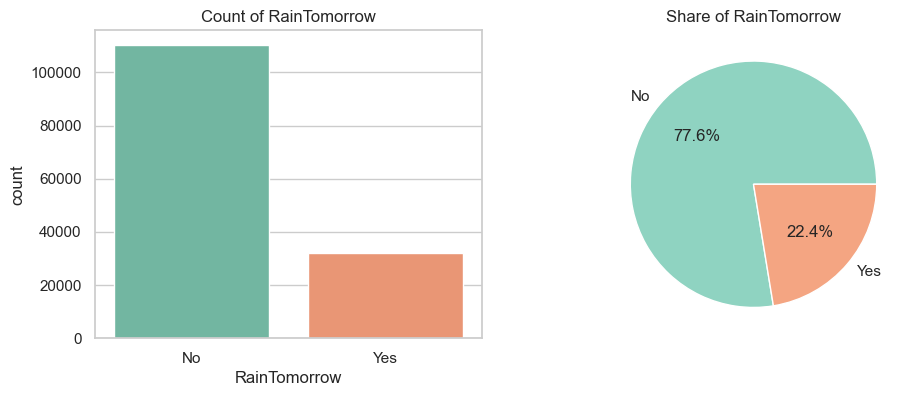

RainTomorrow
No     0.776
Yes    0.224
Name: proportion, dtype: float64


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='RainTomorrow', data=df, ax=ax[0], palette='Set2', hue='RainTomorrow', legend=False)
ax[0].set_title('Count of RainTomorrow')
df['RainTomorrow'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=ax[1], colors=['#8fd3c1', '#f4a582'])
ax[1].set_ylabel('')
ax[1].set_title('Share of RainTomorrow')
plt.show()

print(df['RainTomorrow'].value_counts(normalize=True).round(3))

> **ข้อมูลไม่สมดุล (Imbalanced):** วันฝนไม่ตก ~78% ฝนตก ~22%
> หากทำนายว่า "ไม่ตก" ทุกวัน จะได้ Accuracy ≈ 78% ทันทีโดยไม่ต้องมีโมเดล → เรียกว่า **Null Accuracy**
> ดังนั้นโมเดลต้องได้ **มากกว่า 78%** ถึงจะมีประโยชน์ และต้องดู Precision/Recall ประกอบด้วย

### 5.2 ตรวจ Outlier ด้วย Boxplot และ Histogram

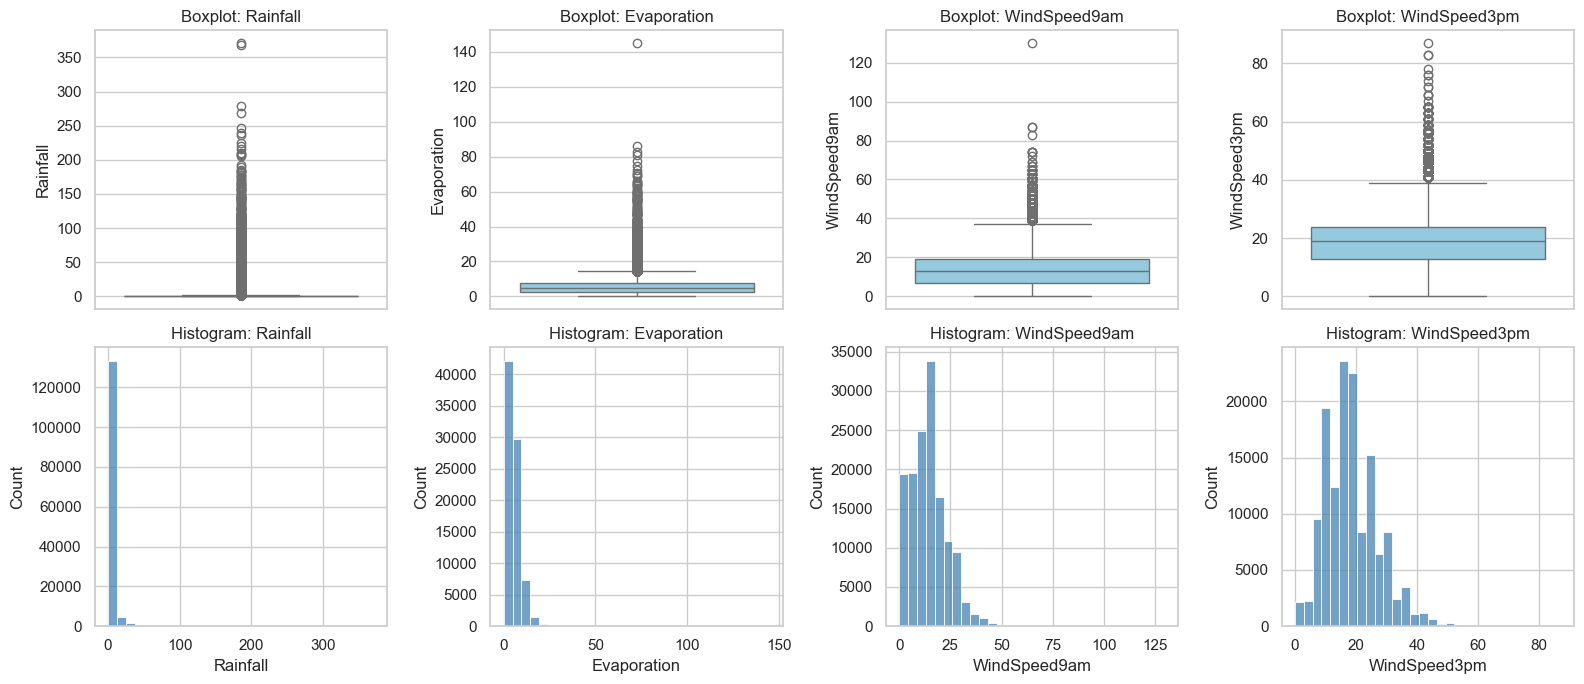

In [13]:
outlier_cols = ['Rainfall', 'Evaporation', 'WindSpeed9am', 'WindSpeed3pm']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, col in enumerate(outlier_cols):
    sns.boxplot(y=df[col], ax=axes[0, i], color='skyblue')
    axes[0, i].set_title(f'Boxplot: {col}')
    sns.histplot(df[col], bins=30, ax=axes[1, i], color='steelblue')
    axes[1, i].set_title(f'Histogram: {col}')
plt.tight_layout()
plt.show()

> **ข้อสังเกต:** ทั้ง 4 ตัวมีจุดนอกกล่องจำนวนมาก และ Histogram เบ้ขวา → ต้องจัดการ Outlier

### 5.3 คำนวณขอบเขต Outlier ด้วย IQR
สูตร: `IQR = Q3 − Q1`, ขอบบน = `Q3 + k × IQR`
- ปกติ `k = 1.5` แต่ข้อมูลนี้เบ้มาก จึงใช้ `k = 3` (Extreme outlier) ตามต้นฉบับ เพื่อไม่ตัดข้อมูลมากเกินไป

In [14]:
for col in outlier_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 3 * iqr
    n_out = (df[col] > upper).sum()
    print(f"{col:13s} Q1={q1:6.1f}  Q3={q3:6.1f}  ขอบบน={upper:6.1f}  → outlier {n_out:6d} แถว ({n_out/len(df):.1%})")

Rainfall      Q1=   0.0  Q3=   0.8  ขอบบน=   3.2  → outlier  20462 แถว (14.4%)
Evaporation   Q1=   2.6  Q3=   7.4  ขอบบน=  21.8  → outlier    471 แถว (0.3%)
WindSpeed9am  Q1=   7.0  Q3=  19.0  ขอบบน=  55.0  → outlier    107 แถว (0.1%)
WindSpeed3pm  Q1=  13.0  Q3=  24.0  ขอบบน=  57.0  → outlier     81 แถว (0.1%)


> **หมายเหตุ:** ตรงนี้คำนวณจากข้อมูลทั้งหมดเพื่อ **ดูภาพรวม** เท่านั้น ตอนจัดการจริง (ขั้นที่ 6) จะคำนวณขอบใหม่จาก **Train Set**

### 5.4 ความสัมพันธ์ระหว่างตัวแปรกับฝนในวันถัดไป

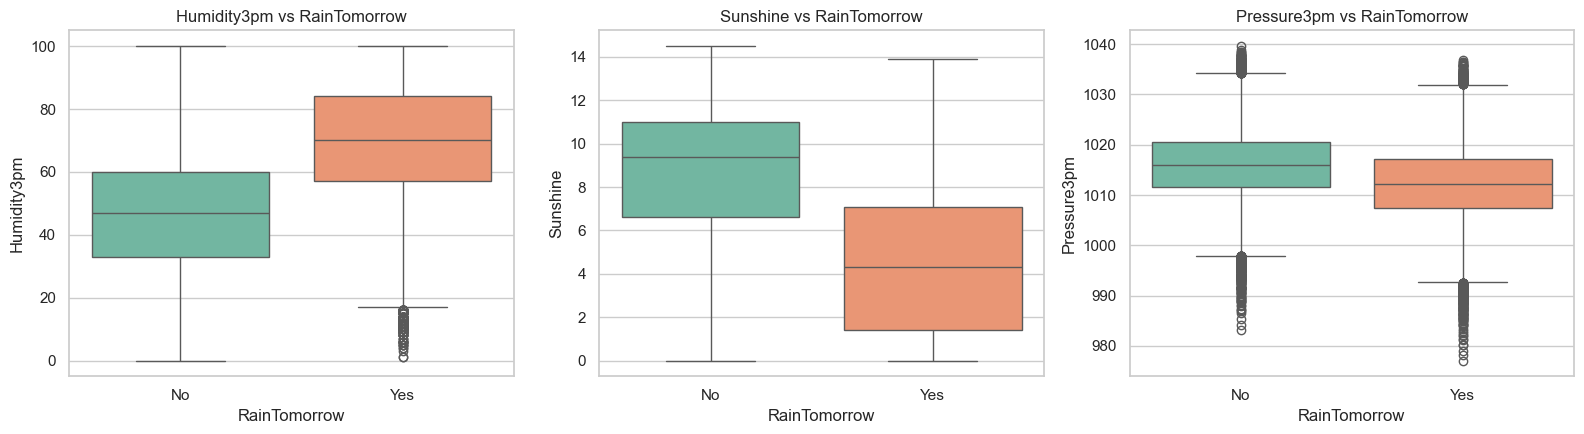

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x='RainTomorrow', y='Humidity3pm', data=df, ax=axes[0], palette='Set2', hue='RainTomorrow', legend=False)
axes[0].set_title('Humidity3pm vs RainTomorrow')
sns.boxplot(x='RainTomorrow', y='Sunshine', data=df, ax=axes[1], palette='Set2', hue='RainTomorrow', legend=False)
axes[1].set_title('Sunshine vs RainTomorrow')
sns.boxplot(x='RainTomorrow', y='Pressure3pm', data=df, ax=axes[2], palette='Set2', hue='RainTomorrow', legend=False)
axes[2].set_title('Pressure3pm vs RainTomorrow')
plt.tight_layout()
plt.show()

> **ข้อสังเกต:** วันก่อนฝนตก: **ความชื้นตอนบ่ายสูงกว่า**, **แดดน้อยกว่า**, **ความกดอากาศต่ำกว่า** → ตัวแปรเหล่านี้น่าจะเป็น Feature ที่ดี

### 5.5 ความสัมพันธ์ระหว่างฝนวันนี้กับฝนวันถัดไป (Categorical × Categorical)

สัดส่วนฝนพรุ่งนี้ แยกตามฝนวันนี้:
RainTomorrow     No    Yes
RainToday                 
No            0.848  0.152
Yes           0.536  0.464


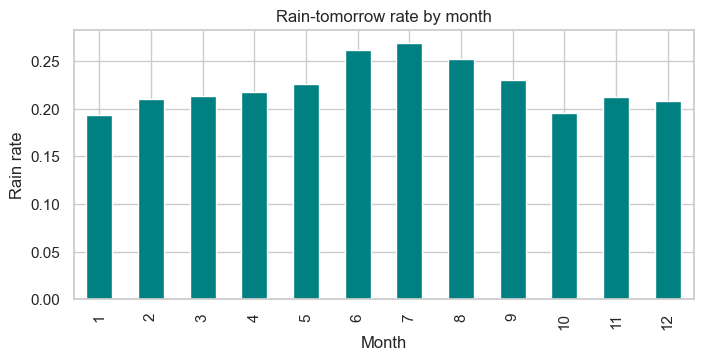

In [16]:
ct = pd.crosstab(df['RainToday'], df['RainTomorrow'], normalize='index').round(3)
print("สัดส่วนฝนพรุ่งนี้ แยกตามฝนวันนี้:")
print(ct)

monthly = df.groupby('Month')['RainTomorrow'].apply(lambda s: (s == 'Yes').mean())
plt.figure(figsize=(8, 3.5))
monthly.plot(kind='bar', color='teal')
plt.ylabel('Rain rate')
plt.title('Rain-tomorrow rate by month')
plt.show()

> **ข้อสังเกต:** ถ้าวันนี้ฝนตก โอกาสพรุ่งนี้ตกสูงขึ้นมาก (~46% เทียบกับ ~15%) และเดือนกลางปี (ฤดูหนาวของออสเตรเลีย) ฝนตกบ่อยกว่า

### 5.6 Correlation ระหว่างตัวแปรตัวเลข

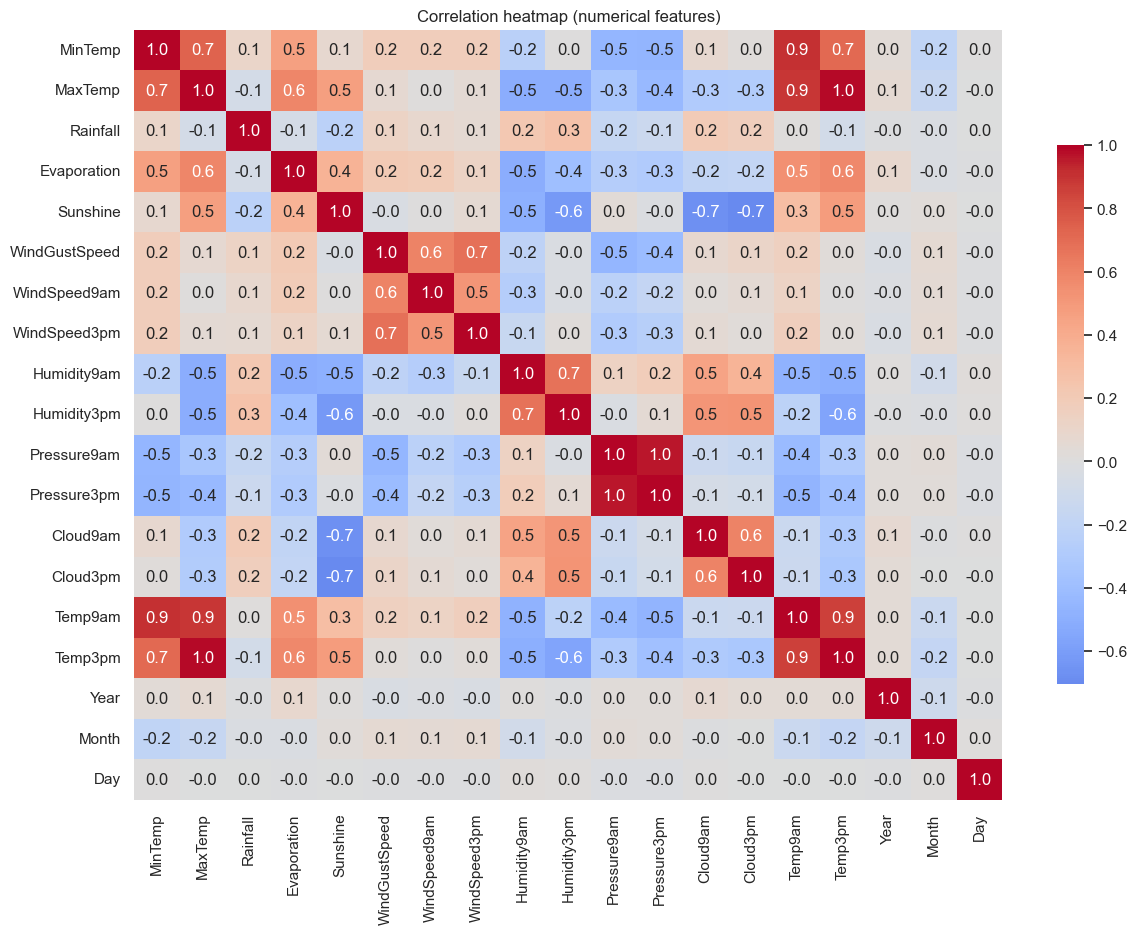

In [17]:
num_cols = [c for c in df.columns if df[c].dtype != 'object']
plt.figure(figsize=(14, 10))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.1f', cmap='coolwarm', center=0, cbar_kws={'shrink': .7})
plt.title('Correlation heatmap (numerical features)')
plt.show()

> **ข้อสังเกต:** คู่ที่สัมพันธ์กันสูงมาก เช่น `MaxTemp`–`Temp3pm`, `Pressure9am`–`Pressure3pm` (≈ 0.9+) แปลว่าข้อมูลซ้ำซ้อนกัน
> (Multicollinearity) — ไม่ทำให้ Tree เสีย แต่ทำให้ค่า coefficient ของ Logistic Regression ตีความยากขึ้น

---
# ขั้นที่ 6: เตรียมข้อมูลสำหรับโมเดล (Preprocessing)

### 6.1 แยก X (Feature) และ y (Target)
แปลง Target เป็นตัวเลข: `Yes → 1` (ฝนตก = คลาสที่สนใจ / Positive), `No → 0`

In [18]:
X = df.drop(columns='RainTomorrow')
y = (df['RainTomorrow'] == 'Yes').astype(int)

print("X:", X.shape, "  y:", y.shape)
print(y.value_counts())

X: (142193, 24)   y: (142193,)
RainTomorrow
0    110316
1     31877
Name: count, dtype: int64


### 6.2 แบ่ง Train / Test (80 / 20)
- `stratify=y` → ให้สัดส่วนฝนตก/ไม่ตกใน Train และ Test เท่ากัน (สำคัญมากกับข้อมูลไม่สมดุล)
- `random_state=0` → สุ่มแบบเดิมทุกครั้ง ผลลัพธ์จะเหมือนเดิม

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("สัดส่วนฝนตก  Train:", round(y_train.mean(), 3), " Test:", round(y_test.mean(), 3))

Train: (113754, 24)  Test: (28439, 24)
สัดส่วนฝนตก  Train: 0.224  Test: 0.224


### 6.3 จัดการ Outlier ด้วยการ "ตัดเพดาน" (Capping / Top-coding)
แทนที่จะลบแถวทิ้ง (เสียข้อมูล) เราจะ **แทนค่าที่เกินขอบบนด้วยค่าขอบบน** ขอบบนคำนวณจาก Train Set

> **ทำไมต้องทำก่อนเติมค่าหาย?** ถ้าเติม median ก่อน คอลัมน์ที่มีค่าหายจำนวนมาก (เช่น `Evaporation` หาย ~43%)
> จะมีค่า median ซ้ำกันจำนวนมาก ทำให้ IQR แคบผิดปกติ และตัดเพดานต่ำเกินไป (`quantile()` ข้ามค่า NaN ให้อยู่แล้ว)

In [20]:
X_train = X_train.copy()
X_test  = X_test.copy()

for col in outlier_cols:
    q1, q3 = X_train[col].quantile(0.25), X_train[col].quantile(0.75)   # ← จาก Train เท่านั้น
    upper = q3 + 3 * (q3 - q1)
    X_train[col] = X_train[col].clip(upper=upper)
    X_test[col]  = X_test[col].clip(upper=upper)
    print(f"{col:13s} ตัดเพดานที่ {upper:.1f}  → max ใหม่ Train={X_train[col].max():.1f}, Test={X_test[col].max():.1f}")

Rainfall      ตัดเพดานที่ 2.4  → max ใหม่ Train=2.4, Test=2.4
Evaporation   ตัดเพดานที่ 21.8  → max ใหม่ Train=21.8, Test=21.8
WindSpeed9am  ตัดเพดานที่ 55.0  → max ใหม่ Train=55.0, Test=55.0
WindSpeed3pm  ตัดเพดานที่ 57.0  → max ใหม่ Train=57.0, Test=57.0


### 6.4 เติมค่าหาย (Imputation) ด้วยค่าจาก Train Set
| ชนิด | วิธี | เหตุผล |
|---|---|---|
| Numerical | **Median** | ทนต่อ Outlier มากกว่า Mean (ข้อมูลชุดนี้มี Outlier จำนวนมาก) |
| Categorical | **Mode** (ค่าที่พบบ่อยที่สุด) | ค่าข้อความหาค่าเฉลี่ยไม่ได้ |

In [21]:
categorical = [c for c in X_train.columns if X_train[c].dtype == 'object']
numerical   = [c for c in X_train.columns if X_train[c].dtype != 'object']

for col in numerical:
    median = X_train[col].median()                    # ← ค่าจาก Train เท่านั้น
    X_train[col] = X_train[col].fillna(median)
    X_test[col]  = X_test[col].fillna(median)

for col in categorical:
    mode = X_train[col].mode()[0]                     # ← ค่าจาก Train เท่านั้น
    X_train[col] = X_train[col].fillna(mode)
    X_test[col]  = X_test[col].fillna(mode)

print("ค่าหายที่เหลือ  Train:", X_train.isnull().sum().sum(), "  Test:", X_test.isnull().sum().sum())

ค่าหายที่เหลือ  Train: 0   Test: 0


### 6.5 แปลงข้อความเป็นตัวเลข (Encoding)
| คอลัมน์ | วิธี | เหตุผล |
|---|---|---|
| `RainToday` (Yes/No) | Map เป็น 1/0 | มีเพียง 2 ค่า ใช้คอลัมน์เดียวเพียงพอ |
| `Location`, `WindGustDir`, `WindDir9am`, `WindDir3pm` | **One-Hot Encoding** | ไม่มีลำดับ (ทิศ N ไม่ได้ "มากกว่า" ทิศ S) |

> **ข้อควรระวัง:** หลัง One-Hot ต้องทำให้ **คอลัมน์ของ Test ตรงกับ Train** ด้วย `reindex` (กันกรณีบางหมวดมีใน Train แต่ไม่มีใน Test)

In [22]:
X_train['RainToday'] = (X_train['RainToday'] == 'Yes').astype(int)
X_test['RainToday']  = (X_test['RainToday']  == 'Yes').astype(int)

onehot_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']
X_train = pd.get_dummies(X_train, columns=onehot_cols, dtype=int)
X_test  = pd.get_dummies(X_test,  columns=onehot_cols, dtype=int)
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)   # จัดคอลัมน์ให้ตรงกัน

print("จำนวน Feature หลัง Encode:", X_train.shape[1])
X_train.iloc[:3, -8:]

จำนวน Feature หลัง Encode: 117


,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
1055,0,0,0,0,0,0,0,1
142359,0,0,0,0,0,0,0,0
128926,0,0,1,0,0,0,0,0


### 6.6 ปรับสเกล (Feature Scaling) ด้วย MinMaxScaler
แปลงทุกคอลัมน์ให้อยู่ช่วง 0–1 → Logistic Regression เรียนรู้ได้เร็วและเสถียรขึ้น (Tree ไม่จำเป็นต้อง Scale แต่ใช้ข้อมูลชุดเดียวกันได้ ไม่เสียหาย)

`fit_transform` กับ Train (เรียนค่า min/max) → `transform` กับ Test (ใช้ค่า min/max ของ Train)

In [23]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
feature_names = X_train.columns
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names)
X_test  = pd.DataFrame(scaler.transform(X_test),      columns=feature_names)

X_train.describe().loc[['min', 'max']].iloc[:, :8]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


> **ผลลัพธ์:** ข้อมูลพร้อมแล้ว: ไม่มีค่าหาย, ไม่มีข้อความ, สเกล 0–1, Train และ Test มีคอลัมน์ตรงกัน

---
# ขั้นที่ 7: โมเดลที่ 1 — Logistic Regression

### หลักการ
1. คำนวณคะแนน `z = w₁x₁ + w₂x₂ + … + b`
2. แปลงเป็นความน่าจะเป็นด้วย **Sigmoid**: `p = 1 / (1 + e⁻ᶻ)` (ได้ค่า 0–1 เสมอ)
3. ถ้า `p ≥ 0.5` → ทำนายว่า "ฝนตก" (1) มิฉะนั้นทำนายว่า "ไม่ตก" (0)

ค่า `0.5` เรียกว่า **Threshold** ปรับได้ (ดูข้อ 7.6)

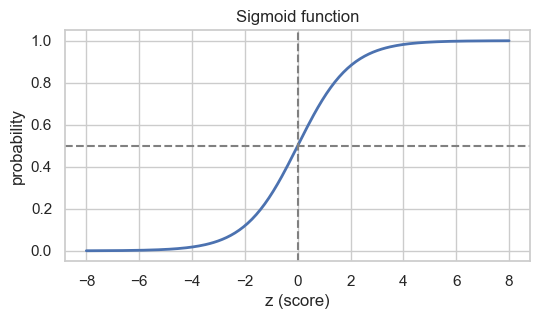

In [24]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3))
plt.plot(z, 1 / (1 + np.exp(-z)), lw=2)
plt.axhline(0.5, ls='--', c='gray'); plt.axvline(0, ls='--', c='gray')
plt.xlabel('z (score)'); plt.ylabel('probability'); plt.title('Sigmoid function')
plt.show()

### 7.1 เทรนโมเดลและทำนาย

In [25]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(solver='liblinear', random_state=0)
logreg.fit(X_train, y_train)

y_pred_lr = logreg.predict(X_test)                 # คำตอบ 0/1
y_prob_lr = logreg.predict_proba(X_test)[:, 1]     # ความน่าจะเป็นที่ฝนจะตก

pd.DataFrame({'Actual': y_test.values[:8], 'Predicted': y_pred_lr[:8],
              'P(rain)': y_prob_lr[:8].round(3)})

,Actual,Predicted,P(rain)
0,0,0,0.324
1,1,0,0.210
2,0,0,0.057
3,0,0,0.441
4,0,0,0.077
5,0,0,0.158
6,0,0,0.255
7,0,0,0.476


### 7.2 Accuracy: เทียบ Train vs Test และเทียบกับ Null Accuracy

In [26]:
from sklearn.metrics import accuracy_score

train_acc = logreg.score(X_train, y_train)
test_acc  = accuracy_score(y_test, y_pred_lr)
null_acc  = 1 - y_test.mean()       # เดาว่า "ไม่ตก" ทุกวัน

print(f"Train accuracy : {train_acc:.4f}")
print(f"Test accuracy  : {test_acc:.4f}")
print(f"Null accuracy  : {null_acc:.4f}  (เดา 'ไม่ตก' ทุกวัน)")

Train accuracy : 0.8485
Test accuracy  : 0.8464
Null accuracy  : 0.7758  (เดา 'ไม่ตก' ทุกวัน)


> **การตีความผล:** Train ≈ Test → **ไม่ Overfitting** และ Test (≈0.85) สูงกว่า Null accuracy (≈0.78) → โมเดลมีประโยชน์จริง

### 7.3 ทดลองปรับ Hyperparameter `C` (ความแรงของ Regularization)
- `C` เล็ก → ลงโทษ coefficient แรง → โมเดลเรียบง่าย (เสี่ยง Underfit)
- `C` ใหญ่ → ลงโทษน้อย → โมเดลซับซ้อน (เสี่ยง Overfit)

In [27]:
for C in [0.01, 1, 100]:
    m = LogisticRegression(C=C, solver='liblinear', random_state=0).fit(X_train, y_train)
    print(f"C={C:<6} Train={m.score(X_train, y_train):.4f}  Test={m.score(X_test, y_test):.4f}")

C=0.01   Train=0.8421  Test=0.8398


C=1      Train=0.8485  Test=0.8464


C=100    Train=0.8486  Test=0.8461


### 7.4 Confusion Matrix: รูปแบบการทำนายถูกและผิด

ใน scikit-learn: **แถว = ค่าจริง**, **คอลัมน์ = ค่าที่ทำนาย** (เรียงคลาส 0, 1)

| | ทำนาย 0 (ไม่ตก) | ทำนาย 1 (ตก) |
|---|---|---|
| **จริง 0 (ไม่ตก)** | **TN** | **FP** (เตือนฝนแต่ไม่ตก) |
| **จริง 1 (ตก)** | **FN** (ไม่เตือนแต่ฝนตก) | **TP** |

> **ข้อควรระวัง:** บางบทความ (รวมถึงต้นฉบับ) อ่านตำแหน่งสลับกัน ให้ยึดตารางนี้ หรือใช้ `cm.ravel()` ซึ่งคืนค่าเรียง `TN, FP, FN, TP` เสมอ

TN=20829  FP=1235  FN=3133  TP=3242


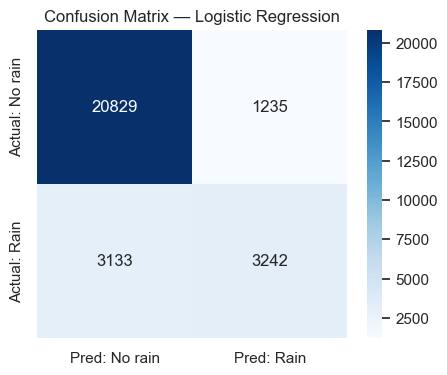

In [28]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)
TN, FP, FN, TP = cm.ravel()
print(f"TN={TN}  FP={FP}  FN={FN}  TP={TP}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: No rain', 'Pred: Rain'], yticklabels=['Actual: No rain', 'Actual: Rain'])
plt.title('Confusion Matrix — Logistic Regression')
plt.show()

### 7.5 Metrics จาก Confusion Matrix

| Metric | สูตร | ความหมาย (โจทย์ฝน) |
|---|---|---|
| **Accuracy** | (TP+TN) / ทั้งหมด | ทำนายถูกกี่ % |
| **Precision** | TP / (TP+FP) | ที่บอกว่า "ฝนตก" ถูกจริงกี่ % |
| **Recall (Sensitivity)** | TP / (TP+FN) | วันฝนตกจริง ตรวจพบได้กี่ % |
| **Specificity** | TN / (TN+FP) | วันไม่ตกจริง ทำนายถูกกี่ % |
| **F1-score** | 2·P·R / (P+R) | ค่าเฉลี่ยแบบสมดุลของ Precision กับ Recall |

In [29]:
precision   = TP / (TP + FP)
recall      = TP / (TP + FN)
specificity = TN / (TN + FP)
f1          = 2 * precision * recall / (precision + recall)

print(f"Accuracy    : {(TP + TN) / cm.sum():.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")

Accuracy    : 0.8464
Precision   : 0.7241
Recall      : 0.5085
Specificity : 0.9440
F1-score    : 0.5975


ใช้ `classification_report` ได้ผลเดียวกันในบรรทัดเดียว (แถว `1` คือคลาสฝนตก)

In [30]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_lr, target_names=['No rain (0)', 'Rain (1)']))

              precision    recall  f1-score   support

 No rain (0)       0.87      0.94      0.91     22064
    Rain (1)       0.72      0.51      0.60      6375

    accuracy                           0.85     28439
   macro avg       0.80      0.73      0.75     28439
weighted avg       0.84      0.85      0.84     28439



> **การตีความผล:** Precision ของฝนตกค่อนข้างดี (~0.72) แต่ **Recall เพียง ~0.51** → วันที่ฝนตกจริง โมเดลพลาดไปเกือบครึ่ง
> สาเหตุหลักคือข้อมูลไม่สมดุล โมเดลจึงเอนไปทาง "ไม่ตก" → แก้ได้ด้วยการลด Threshold

### 7.6 ปรับ Threshold: แลก Precision กับ Recall

In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred_t = (y_prob_lr >= t).astype(int)
    rows.append({'Threshold': t,
                 'Accuracy':  accuracy_score(y_test, pred_t),
                 'Precision': precision_score(y_test, pred_t),
                 'Recall':    recall_score(y_test, pred_t),
                 'F1':        f1_score(y_test, pred_t)})
pd.DataFrame(rows).round(3)

,Threshold,Accuracy,Precision,Recall,F1
0,0.2,0.777,0.502,0.794,0.615
1,0.3,0.825,0.593,0.693,0.639
2,0.4,0.842,0.663,0.597,0.629
3,0.5,0.846,0.724,0.509,0.597
4,0.6,0.842,0.777,0.413,0.539


> **หมายเหตุ:** Threshold ต่ำลง → Recall สูงขึ้น (จับวันฝนตกได้มากขึ้น) แต่ Precision ลดลง (เตือนผิดบ่อยขึ้น)
> **เลือกตามธุรกิจ:** ถ้าการพลาดวันฝนตกมีต้นทุนสูง (เช่น จัดงานกลางแจ้ง) ให้ใช้ Threshold ต่ำลง

### 7.7 ROC Curve และ AUC
- ROC = กราฟ True Positive Rate (Recall) เทียบ False Positive Rate ที่ **ทุก Threshold**
- **AUC** = พื้นที่ใต้กราฟ: 1.0 = สมบูรณ์แบบ, 0.5 = เทียบเท่าการสุ่ม (เส้นทแยง)

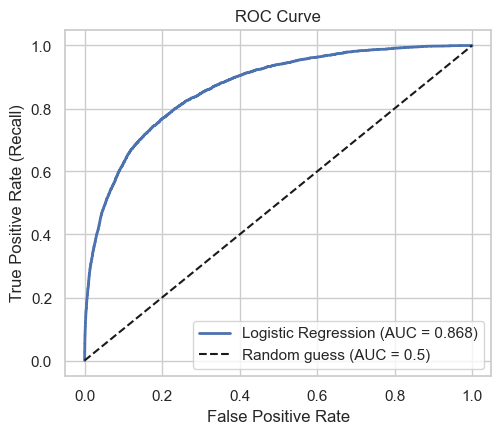

In [32]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, lw=2, label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve'); plt.legend(loc='lower right')
plt.show()

### 7.8 k-Fold Cross-Validation: ความเสถียรของผลลัพธ์
แบ่ง Train เป็น 5 ส่วน สลับกันเป็นชุดทดสอบ → ได้คะแนน 5 ค่า ถ้าใกล้กันแปลว่าโมเดลเสถียร

In [33]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = cross_val_score(LogisticRegression(solver='liblinear', random_state=0),
                            X_train, y_train, cv=skf, scoring='accuracy')
print("Accuracy แต่ละ Fold:", cv_scores.round(4))
print(f"เฉลี่ย {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Accuracy แต่ละ Fold: [0.8466 0.851  0.8513 0.8462 0.8453]
เฉลี่ย 0.8481 ± 0.0025


### 7.9 หา `C` ที่ดีที่สุดด้วย GridSearchCV
GridSearchCV = ทดลองทุกค่าที่กำหนด × Cross-Validation แล้วเลือกค่าที่ดีที่สุดให้อัตโนมัติ (ใช้ Train เท่านั้น)

In [34]:
from sklearn.model_selection import GridSearchCV

grid_lr = GridSearchCV(LogisticRegression(solver='liblinear', random_state=0),
                       param_grid={'C': [0.01, 0.1, 1, 10, 100]},
                       cv=skf, scoring='roc_auc')
grid_lr.fit(X_train, y_train)

print("C ที่ดีที่สุด:", grid_lr.best_params_)
print(f"CV ROC-AUC ที่ดีที่สุด: {grid_lr.best_score_:.4f}")
pd.DataFrame(grid_lr.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']].round(4)

C ที่ดีที่สุด: {'C': 100}
CV ROC-AUC ที่ดีที่สุด: 0.8710


,param_C,mean_test_score,std_test_score
0,0.01,0.8616,0.0038
1,0.10,0.8686,0.0036
2,1.00,0.8708,0.0037
3,10.00,0.8710,0.0037
4,100.00,0.8710,0.0037


In [35]:
best_lr = grid_lr.best_estimator_      # โมเดลที่ดีที่สุด (เทรนบน Train ทั้งหมดแล้ว)

### 7.10 การวิเคราะห์ผล Logistic Regression

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| ดีกว่า Baseline หรือไม่ | Test Acc **0.846** vs Null **0.776** | สูงกว่าการทำนายว่า "ไม่ตก" ทุกวันประมาณ 7 จุด (ส่วนต่างน้อยกว่าที่ตัวเลข 85% อาจทำให้เข้าใจ) |
| Overfit หรือไม่ | Train 0.849 vs Test 0.846 | แทบเท่ากัน → ไม่ Overfit |
| เสถียรหรือไม่ | CV 0.848 ± 0.003 | คะแนน 5 รอบแทบเท่ากัน |
| บอกว่า "ฝนตก" เชื่อได้เพียงใด? | Precision **0.72** | บอกว่าตก 4 ครั้ง ถูก ~3 ครั้ง |
| วันฝนตกจริงตรวจพบได้เพียงใด? | Recall **0.51** | จุดอ่อนหลัก: จากวันฝนตกจริง 6,375 วัน ตรวจพบ 3,242 / **พลาด 3,133 วัน** |
| วันไม่ตกทำนายถูกเพียงใด? | Specificity 0.94 | เตือนผิด (FP) เพียง 1,235 จาก 22,064 วัน |
| แยกสองคลาสได้ดีเพียงใด? | ROC-AUC **0.868** | ระดับดี (0.5 = เทียบเท่าการสุ่ม, 1.0 = สมบูรณ์แบบ) |
| `C` มีผลหรือไม่ | C = 0.01 → 0.840, C = 1 หรือ 100 → 0.846 | แทบไม่มีผล — โมเดลไม่ได้ Overfit จึงไม่ต้องพึ่ง Regularization มาก |
| ปรับ Threshold ช่วยหรือไม่ | Threshold 0.3 → Recall 0.69, Precision 0.59, **F1 0.64** (สูงสุด) | แลก Precision เล็กน้อย เพื่อจับวันฝนตกได้เพิ่ม ~18 จุด |

> **สรุป:** โมเดลเสถียรและไม่ Overfit, Precision ดี แต่ **Recall ต่ำเพราะข้อมูลไม่สมดุล** (ฝนตกเพียง 22%)
> ถ้าการพลาดวันฝนตกมีความเสียหายสูง ควรใช้ Threshold ≈ 0.3 แทน 0.5

---
# ขั้นที่ 8: โมเดลที่ 2 — Decision Tree

### หลักการ
สร้าง "ต้นไม้คำถาม Yes/No" เช่น *ความชื้นบ่าย > 70%?* → *แดด < 5 ชม.?* → ทำนาย
แต่ละจุดแยกเลือกคำถามที่ทำให้กลุ่มลูก **บริสุทธิ์ที่สุด** (Gini impurity ต่ำสุด)

**จุดอ่อน:** ถ้าไม่จำกัดความลึก ต้นไม้จะ "จำ" ข้อมูล Train ได้หมด → **Overfitting**

### 8.1 ทดลอง: ไม่จำกัดความลึก

In [36]:
from sklearn.tree import DecisionTreeClassifier

tree_full = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print(f"ความลึกของต้นไม้: {tree_full.get_depth()}")
print(f"Train accuracy: {tree_full.score(X_train, y_train):.4f}")
print(f"Test accuracy : {tree_full.score(X_test, y_test):.4f}   ← Overfitting ชัดเจน")

ความลึกของต้นไม้: 42
Train accuracy: 1.0000
Test accuracy : 0.7896   ← Overfitting ชัดเจน


### 8.2 การเลือกความลึกของต้นไม้ (Train vs Test)

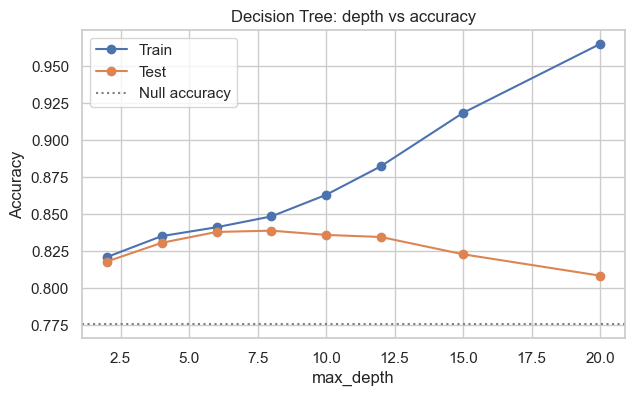

In [37]:
depths = [2, 4, 6, 8, 10, 12, 15, 20]
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    tr.append(m.score(X_train, y_train)); te.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr, 'o-', label='Train'); plt.plot(depths, te, 'o-', label='Test')
plt.axhline(null_acc, ls=':', c='gray', label='Null accuracy')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.title('Decision Tree: depth vs accuracy')
plt.legend(); plt.show()

> **ข้อสังเกต:** ยิ่งลึก Train ยิ่งสูง แต่ Test ขึ้นถึงจุดหนึ่ง (~8) แล้ว **ลดลง** = เริ่ม Overfit

### 8.3 เลือก `max_depth` อย่างถูกวิธีด้วย GridSearchCV
(ไม่ควรเลือกจากกราฟ Test ข้างบน เพราะเท่ากับใช้ Test ในการตัดสินใจ)

In [38]:
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=0),
                       param_grid={'max_depth': [4, 6, 8, 10, 12], 'min_samples_leaf': [1, 20, 50]},
                       cv=skf, scoring='roc_auc', n_jobs=-1)
grid_dt.fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
print("ค่าที่ดีที่สุด:", grid_dt.best_params_, f" CV ROC-AUC = {grid_dt.best_score_:.4f}")

ค่าที่ดีที่สุด: {'max_depth': 10, 'min_samples_leaf': 50}  CV ROC-AUC = 0.8526


### 8.4 ดูหน้าตาต้นไม้ (3 ชั้นแรก) และ Feature Importance

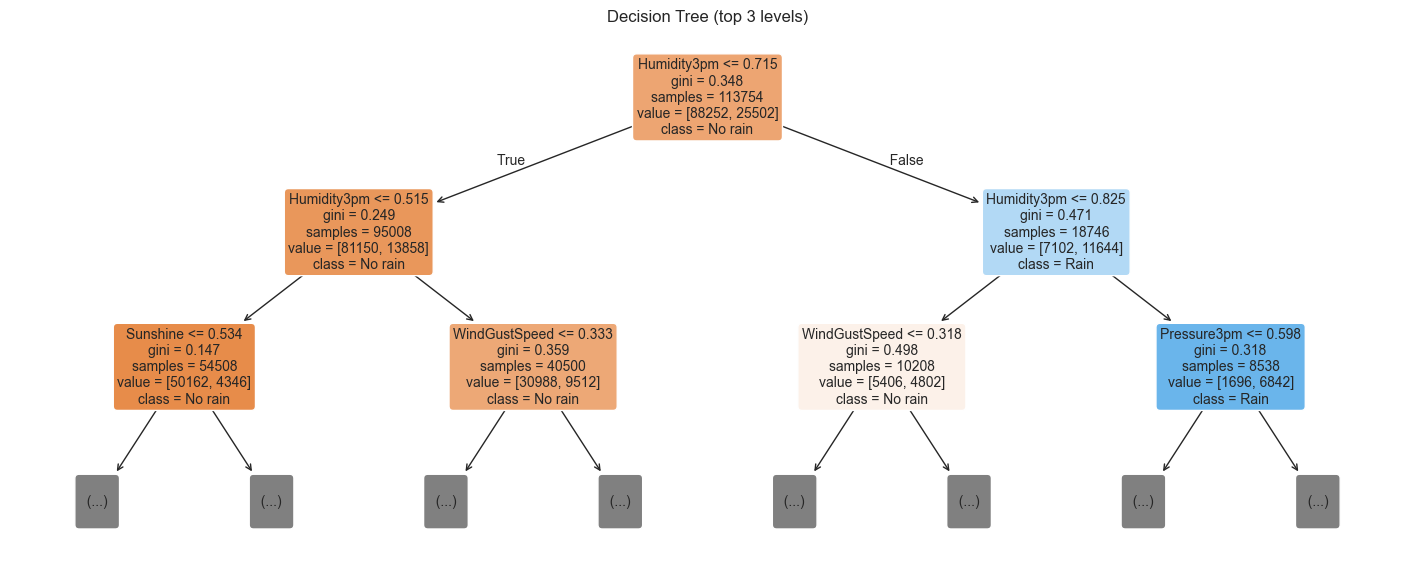

In [39]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 7))
plot_tree(best_dt, max_depth=2, feature_names=feature_names, class_names=['No rain', 'Rain'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (top 3 levels)')
plt.show()

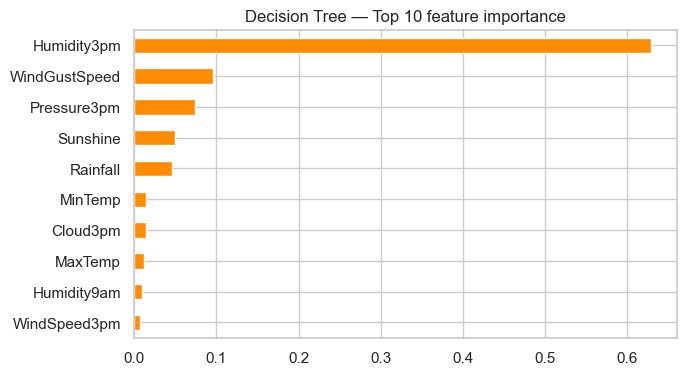

In [40]:
imp_dt = pd.Series(best_dt.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
imp_dt.sort_values().plot(kind='barh', figsize=(7, 4), color='darkorange', title='Decision Tree — Top 10 feature importance')
plt.show()

> **ข้อสังเกต:** `Humidity3pm` สำคัญที่สุด สอดคล้องกับที่เห็นใน EDA (ข้อ 5.4)

### 8.5 ผลบน Test Set

In [41]:
pred_dt = best_dt.predict(X_test)
print(f"Train accuracy: {best_dt.score(X_train, y_train):.4f}")
print(f"Test accuracy : {accuracy_score(y_test, pred_dt):.4f}")
print(f"ROC-AUC       : {roc_auc_score(y_test, best_dt.predict_proba(X_test)[:, 1]):.4f}\n")
print(classification_report(y_test, pred_dt, target_names=['No rain (0)', 'Rain (1)']))

Train accuracy: 0.8535
Test accuracy : 0.8374
ROC-AUC       : 0.8503

              precision    recall  f1-score   support

 No rain (0)       0.86      0.94      0.90     22064
    Rain (1)       0.70      0.49      0.57      6375

    accuracy                           0.84     28439
   macro avg       0.78      0.71      0.74     28439
weighted avg       0.83      0.84      0.83     28439



### 8.6 การวิเคราะห์ผล Decision Tree

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| ไม่จำกัดความลึกเป็นอย่างไร? | ลึก 42 ชั้น, Train **1.000** vs Test **0.790** | Overfit หนัก — จำข้อมูล Train ได้หมด และสูงกว่า Null accuracy (0.776) เพียงเล็กน้อย |
| หลังจูนด้วย GridSearchCV | `max_depth=10`, `min_samples_leaf=50` → Train 0.854 vs Test **0.837** | ช่องว่างเหลือ ~1.6 จุด แก้ Overfit ได้ |
| Precision / Recall / F1 (ฝนตก) | 0.70 / 0.49 / 0.57 | Recall ต่ำแบบเดียวกับ Logistic Regression และต่ำกว่าเล็กน้อยทุกตัว |
| ROC-AUC | **0.850** | ต่ำสุดในสามโมเดล |
| ใช้ Feature อะไรตัดสิน? | `Humidity3pm` สำคัญ ~0.63 (เกินครึ่ง) | ต้นไม้ต้นเดียวพึ่ง Feature เดียวเป็นหลัก |

> **สรุป:** แม่นน้อยที่สุดในสามโมเดล แต่ **ตีความง่ายที่สุด** — วาดเป็นกฎ "ถ้า...แล้ว..." ให้คนทั่วไปอ่านได้
> และเป็นตัวอย่างชัดเจนที่สุดว่า **การจำกัดความลึกสำคัญมาก** กับโมเดล Tree

---
# ขั้นที่ 9: โมเดลที่ 3 — Random Forest

### หลักการ
สร้าง Decision Tree **หลายร้อยต้น** แต่ละต้นเห็นข้อมูลและ Feature ต่างส่วนกัน (สุ่ม) แล้วให้ **โหวต** คำตอบ
→ ความผิดพลาดของแต่ละต้นหักล้างกัน ได้ผลแม่นและเสถียรกว่าต้นไม้ต้นเดียว (ลด Overfitting)

| Hyperparameter | ความหมาย | ค่าที่ใช้ |
|---|---|---|
| `n_estimators` | จำนวนต้นไม้ | 100 |
| `max_depth` | ความลึกสูงสุดของแต่ละต้น | 20 (กันไม่ให้ต้นไม้ใหญ่เกินไป) |
| `n_jobs=-1` | ใช้ CPU ทุก core | เร็วขึ้น |

In [42]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)

print(f"Train accuracy: {rf.score(X_train, y_train):.4f}")
print(f"Test accuracy : {rf.score(X_test, y_test):.4f}")

Train accuracy: 0.9433
Test accuracy : 0.8532


> **ข้อสังเกต:** Train สูงกว่า Test พอสมควร (Overfit บ้าง) แต่ **Test ยังสูงกว่า Decision Tree ต้นเดียว** — นี่คือจุดเด่นของ Ensemble

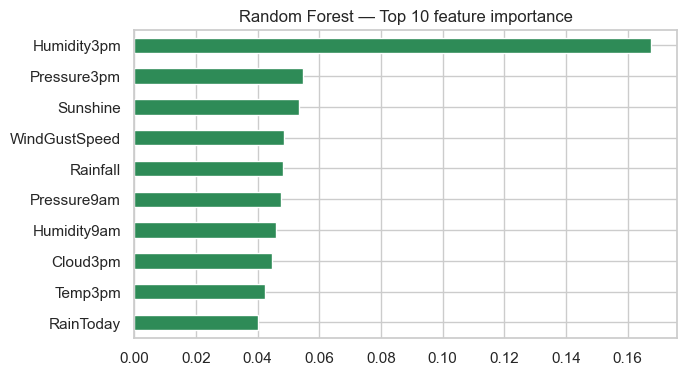

In [43]:
imp_rf = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
imp_rf.sort_values().plot(kind='barh', figsize=(7, 4), color='seagreen', title='Random Forest — Top 10 feature importance')
plt.show()

### 9.1 ผลบน Test Set

In [44]:
pred_rf = rf.predict(X_test)
print(f"ROC-AUC: {roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]):.4f}\n")
print(classification_report(y_test, pred_rf, target_names=['No rain (0)', 'Rain (1)']))

ROC-AUC: 0.8778

              precision    recall  f1-score   support

 No rain (0)       0.86      0.96      0.91     22064
    Rain (1)       0.78      0.48      0.59      6375

    accuracy                           0.85     28439
   macro avg       0.82      0.72      0.75     28439
weighted avg       0.85      0.85      0.84     28439



### 9.2 การวิเคราะห์ผล Random Forest

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| แม่นเพียงใด? | Test Acc **0.853** | สูงสุดในสามโมเดล |
| Overfit หรือไม่ | Train 0.943 vs Test 0.853 | ช่องว่าง ~9 จุด Overfit บ้าง แต่ Test ยังดีที่สุด (แต่ละต้นลึกได้ถึง 20 ชั้น) |
| บอกว่า "ฝนตก" เชื่อได้เพียงใด? | Precision **0.78** | สูงสุด — เตือนผิดน้อยที่สุด |
| วันฝนตกจริงตรวจพบได้เพียงใด? | Recall **0.48** | ต่ำสุดเล็กน้อย — โมเดลมีแนวโน้มทำนายว่าฝนตกเฉพาะเมื่อมีความมั่นใจสูง |
| F1 | 0.595 | ใกล้เคียง Logistic Regression (0.597) |
| ROC-AUC | **0.878** | สูงสุด — แยกวันฝนตก/ไม่ตกได้ดีที่สุด |
| ใช้ Feature อะไรตัดสิน? | `Humidity3pm` ~0.17 ที่เหลือกระจาย ~0.04–0.05 | ใช้ข้อมูลหลายตัวร่วมกัน ไม่พึ่งตัวเดียวแบบ Decision Tree |

> **สรุป:** แม่นที่สุดทั้ง Accuracy, Precision และ AUC เพราะเฉลี่ยคำตอบจากต้นไม้ 100 ต้น
> แต่ Recall ยังต่ำ — ทดลองลด Threshold แบบข้อ 7.6 ได้เช่นกัน (`rf.predict_proba(X_test)[:, 1] >= 0.3`)

---
# ขั้นที่ 10: เปรียบเทียบ 3 โมเดลและเลือกโมเดลที่ดีที่สุด

### 10.1 ตารางเปรียบเทียบ Metrics (บน Test Set)

In [45]:
models = {'Logistic Regression': best_lr, 'Decision Tree': best_dt, 'Random Forest': rf}

results = []
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    results.append({'Model': name,
                    'Train Acc': m.score(X_train, y_train),
                    'Test Acc':  accuracy_score(y_test, pred),
                    'Precision': precision_score(y_test, pred),
                    'Recall':    recall_score(y_test, pred),
                    'F1':        f1_score(y_test, pred),
                    'ROC-AUC':   roc_auc_score(y_test, prob)})

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df.style.format('{:.4f}').highlight_max(axis=0, color='#c7e9c0', subset=['Test Acc', 'Precision', 'Recall', 'F1', 'ROC-AUC'])

,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.8486,0.8461,0.7220,0.5093,0.5973,0.8678
Decision Tree,0.8535,0.8374,0.6954,0.4889,0.5742,0.8503
Random Forest,0.9433,0.8532,0.7800,0.4805,0.5946,0.8778


### 10.2 ROC Curve ของทั้ง 3 โมเดล

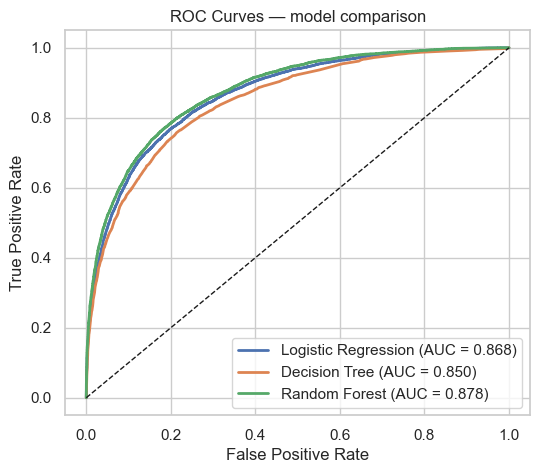

In [46]:
plt.figure(figsize=(6, 5))
for name, m in models.items():
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC Curves — model comparison')
plt.legend(loc='lower right'); plt.show()

### 10.3 Confusion Matrix ของทั้ง 3 โมเดล

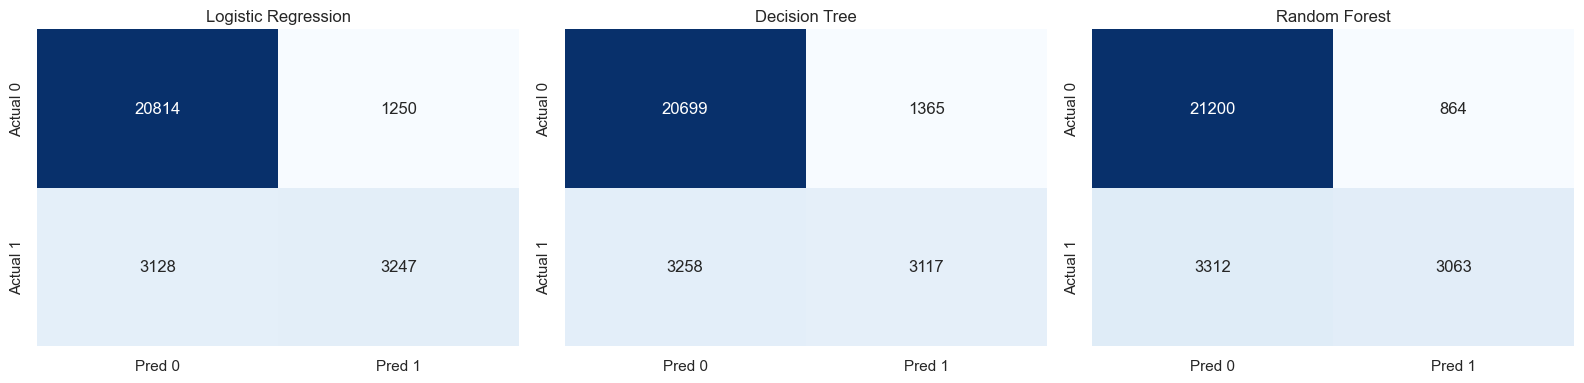

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, m) in zip(axes, models.items()):
    sns.heatmap(confusion_matrix(y_test, m.predict(X_test)), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 10.4 สรุปผลการเปรียบเทียบ

| โมเดล | Test Acc | Precision | Recall | F1 | ROC-AUC | Overfit? | จุดเด่น |
|---|---|---|---|---|---|---|---|
| Logistic Regression | 0.846 | 0.72 | **0.51** | **0.597** | 0.868 | ไม่ | เสถียร เร็ว อธิบายง่าย, F1/Recall สูงสุด |
| Decision Tree | 0.837 | 0.70 | 0.49 | 0.574 | 0.850 | ไม่ (หลังปรับ Hyperparameter) | ตีความง่ายที่สุด |
| Random Forest | **0.853** | **0.78** | 0.48 | 0.595 | **0.878** | เล็กน้อย | แม่นที่สุด, AUC สูงสุด |

**ข้อค้นพบหลัก**
1. **ทุกโมเดลให้ผลดีกว่า Baseline** (Null accuracy 0.776) แต่ส่วนต่างเพียง 6–8 จุด → ต้องรายงาน Null accuracy ด้วยทุกครั้ง
2. **ทั้งสามโมเดลแม่นใกล้เคียงกันมาก** (Accuracy ห่างกันไม่ถึง 2 จุด) โมเดลที่ซับซ้อนขึ้นไม่ได้ช่วยมาก
3. **จุดอ่อนร่วม = Recall ≈ 0.5** มาจากข้อมูลไม่สมดุล ไม่ใช่จากโมเดล → แก้ด้วยการลด Threshold หรือ `class_weight='balanced'`
4. **ความชื้นตอนบ่าย (`Humidity3pm`)** เป็นตัวทำนายที่สำคัญที่สุดในทุกโมเดล ตรงกับ EDA

**คำแนะนำ**
- ต้องการความแม่นสูงสุด → **Random Forest**
- ต้องการโมเดลเรียบง่าย อธิบายได้ ใช้ทรัพยากรน้อย → **Logistic Regression** (เสียความแม่นไปเพียง ~0.7 จุด)
- ใช้จริงควรปรับ Threshold ≈ 0.3 เพื่อให้จับวันฝนตกได้มากขึ้น

> **ตัวอย่างการเขียนสรุปผลในข้อสอบ:**
> *"เลือก Random Forest เพราะได้ Accuracy (0.853) และ ROC-AUC (0.878) สูงสุดบน Test Set และสูงกว่า Null accuracy (0.776)
> แม้ Train/Test ต่างกัน ~9 จุดแต่ Test ยังดีที่สุด ข้อจำกัดคือ Recall ของวันฝนตกเพียง 0.48 เนื่องจากข้อมูลไม่สมดุล
> หากต้องการลดการพลาดวันฝนตก ควรลด Threshold หรือใช้ class_weight='balanced'"*
>
> โครงที่ใช้: (1) เลือกโมเดลอะไร (2) ตัวเลขที่ใช้ตัดสิน (3) เหตุผล (4) ข้อจำกัดและสิ่งที่จะปรับต่อ

---
## รายการตรวจสอบสำหรับการสอบ (Checklist)
- [ ] ลบแถวที่ Target หาย / ตรวจข้อมูลซ้ำ
- [ ] ดูสัดส่วน Target และคำนวณ Null accuracy
- [ ] **Split ก่อน** แล้วค่อยจัด Outlier / เติมค่าหาย / Scale ด้วยค่าจาก Train
- [ ] Encode ข้อความ และจัดคอลัมน์ Test ให้ตรง Train
- [ ] เทรนอย่างน้อย 2–3 โมเดล เทียบ Train vs Test (เช็ค Overfit)
- [ ] รายงาน Confusion Matrix, Precision, Recall, F1, ROC-AUC
- [ ] ใช้ Cross-Validation / GridSearchCV เลือก Hyperparameter (ไม่ใช้ Test)
- [ ] สรุปเลือกโมเดลพร้อมเหตุผล

## แบบฝึกหัด
1. ทดลองเพิ่ม `class_weight='balanced'` ให้ Logistic Regression แล้วดู Recall เปลี่ยนไปอย่างไร
2. เพิ่มโมเดลที่ 4: `KNeighborsClassifier(n_neighbors=15)` แล้วเพิ่มลงในตารางเปรียบเทียบ

In [48]:
# เฉลยข้อ 1
lr_bal = LogisticRegression(solver='liblinear', class_weight='balanced', random_state=0).fit(X_train, y_train)
print(classification_report(y_test, lr_bal.predict(X_test), target_names=['No rain (0)', 'Rain (1)']))
# Recall ของฝนตกเพิ่มขึ้นมาก แต่ Precision ลดลง — ผลคล้ายกับการลด Threshold ในข้อ 7.6

              precision    recall  f1-score   support

 No rain (0)       0.92      0.80      0.86     22064
    Rain (1)       0.53      0.77      0.63      6375

    accuracy                           0.79     28439
   macro avg       0.73      0.79      0.74     28439
weighted avg       0.83      0.79      0.81     28439

